# Pantree: what the data says

This notebook explores the shop's history from the [ecommerce-simulator](https://github.com/Meetpanchal58/ecommerce-simulator)
package: sales over time and sale events, discounts, the shopping funnel, payments, returns, marketing channels,
repeat customers and churn. It ends with the recommendation evaluation results.

Every number below is computed from the data when the notebook runs. The data is simulated (see the README),
so the findings describe how this shop behaves, not a real business.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
SOURCE = ROOT / "data" / "source"   # the ecommerce-simulator tables (python prepare_data.py)
import pyarrow.dataset as ds

def read(name, columns=None):
    path = SOURCE / f"{name}.parquet"
    if path.exists():
        return pd.read_parquet(path, columns=columns)
    return ds.dataset(SOURCE / name, format="parquet", partitioning="hive").to_table(columns=columns).to_pandas()

def rows(name):
    path = SOURCE / f"{name}.parquet"
    return ds.dataset(path if path.exists() else SOURCE / name, format="parquet", partitioning="hive").count_rows()

# Chart style: one categorical palette in fixed order, thin marks, recessive grid.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "lines.linewidth": 2, "font.size": 9,
})

from matplotlib.ticker import PercentFormatter

def hbar(series, title, fmt="{:.1%}", color=SERIES[0], sort=True):
    s = series.sort_values() if sort else series
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(s) + 0.9))
    ax.barh(s.index.astype(str), s.values, color=color, height=0.62)
    for y, v in enumerate(s.values):
        ax.text(v, y, "  " + fmt.format(v), va="center", color=INK, fontsize=8.5)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.margins(x=0.12)
    if "%" in fmt:
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    plt.tight_layout(); plt.show()

# One row per order line; a line's revenue counts once it is delivered, minus any refund.
tx = read("sales")
tx = tx[tx["line_type"].eq("Sale")].copy()
tx["order_timestamp"] = pd.to_datetime(tx["placed_at"])
tx["realized_revenue"] = (tx["net_amount"] - tx["refund_amount"]).where(tx["delivered_at"].notna(), 0.0)
orders = tx.groupby("order_id").agg(customer_id=("customer_id", "first"), order_timestamp=("order_timestamp", "min"),
                                    realized_revenue=("realized_revenue", "sum"))
realized = orders[orders["realized_revenue"] > 0].reset_index()
customers = read("customers"); products = read("product_master")
events = read("sale_events")
events["start_date"] = pd.to_datetime(events["start_date"]); events["end_date"] = pd.to_datetime(events["end_date"])
SUMMARY = {}  # key numbers, written to recommendations/reports/insights_summary.json for the README

## 1. The dataset at a glance

In [2]:
sizes = {name: rows(name) for name in [
    "customers", "product_master", "product_skus", "sales", "clickstream", "impressions",
    "inventory_history", "purchase_orders", "product_reviews", "support_contacts", "sale_events"]}
print(pd.Series(sizes, name="rows").map("{:,}".format).to_string())
buyers = realized["customer_id"].nunique()
print(f"\nCustomers who bought at least once: {buyers:,} of {len(customers):,} ({buyers/len(customers):.1%})")
print(f"Realized revenue: ₹{realized['realized_revenue'].sum():,.0f} from {len(realized):,} paid orders")
print(f"Average order value: ₹{realized['realized_revenue'].mean():,.0f}")
SUMMARY.update(customers=len(customers), buyers=int(buyers), paid_orders=int(len(realized)),
               average_order_value=float(realized["realized_revenue"].mean()))

customers                47,789
product_master            8,727
product_skus             33,588
sales                    88,195
clickstream          11,089,768
impressions          38,874,126
inventory_history       141,272
purchase_orders          41,353
product_reviews          16,475
support_contacts          9,434
sale_events                  58

Customers who bought at least once: 20,295 of 47,789 (42.5%)
Realized revenue: ₹92,706,085 from 53,958 paid orders
Average order value: ₹1,718


## 2. Sales over time and sale events
Monthly realized revenue; shaded months contain a Mega Sale (festivals happen almost every month, so they are not shaded). The shop grows every month,
so each event is compared with the **14 days just before it** (a local baseline), not with the overall average.

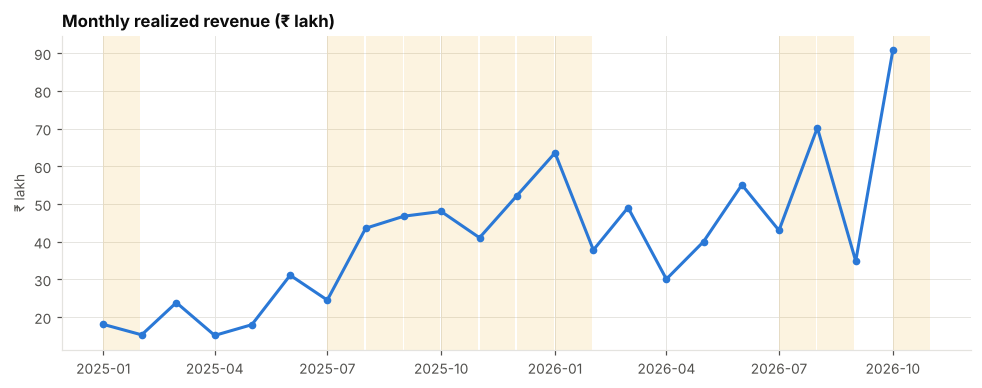

Best month: Oct 2026 (₹90.8 lakh); weakest: Apr 2025 (₹15.2 lakh)


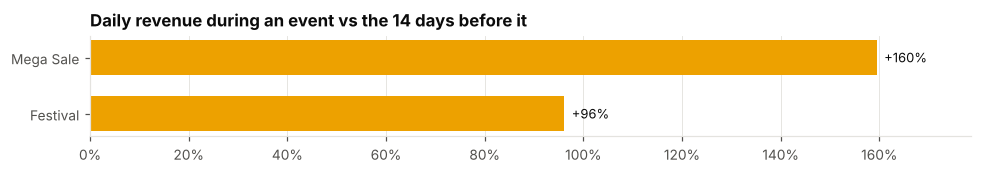

Diwali 2025: +123.7% vs the two weeks before (the simulator gives Diwali 2.0x demand plus extra discounts every year)
Diwali 2026: +124.3% vs the two weeks before (the simulator gives Diwali 2.0x demand plus extra discounts every year)
Average uplift across 31 big events: +115%


In [3]:
monthly = realized.set_index("order_timestamp")["realized_revenue"].resample("MS").sum()
if realized["order_timestamp"].max().day < 25:
    monthly = monthly.iloc[:-1]   # drop the unfinished month
big = events[events["event_type"].isin(["Mega Sale", "Festival"])]
mega = events[events["event_type"].eq("Mega Sale")]
fig, ax = plt.subplots()
for month in monthly.index:
    if ((mega["start_date"] <= month + pd.offsets.MonthEnd(0)) & (mega["end_date"] >= month)).any():
        ax.axvspan(month, month + pd.offsets.MonthEnd(0), color="#eda100", alpha=0.12, lw=0)
ax.plot(monthly.index, monthly.values / 1e5, color=SERIES[0], marker="o", markersize=4)
ax.set_title("Monthly realized revenue (₹ lakh)"); ax.set_ylabel("₹ lakh")
plt.tight_layout(); plt.show()
print(f"Best month: {monthly.idxmax():%b %Y} (₹{monthly.max()/1e5:.1f} lakh); weakest: {monthly.idxmin():%b %Y} (₹{monthly.min()/1e5:.1f} lakh)")

daily = realized.set_index("order_timestamp")["realized_revenue"].resample("D").sum()
uplifts = []
for e in big.itertuples():
    during = daily[e.start_date:e.end_date]
    before = daily[e.start_date - pd.Timedelta(days=14):e.start_date - pd.Timedelta(days=1)]
    if len(during) and len(before) == 14 and e.end_date <= daily.index[-1]:
        uplifts.append((e.name, e.event_type, during.mean() / before.mean() - 1, e.demand_uplift))
uplift = pd.DataFrame(uplifts, columns=["event", "type", "uplift", "configured_demand"])
hbar(uplift.groupby("type")["uplift"].mean(), "Daily revenue during an event vs the 14 days before it",
     fmt="{:+.0%}", color=SERIES[3])
diwali = uplift[uplift["event"].str.contains("Diwali")]
for row in diwali.itertuples():
    print(f"{row.event}: {row.uplift:+.1%} vs the two weeks before "
          f"(the simulator gives Diwali {row.configured_demand:.1f}x demand plus extra discounts every year)")
print(f"Average uplift across {len(uplift)} big events: {uplift['uplift'].mean():+.0%}")
SUMMARY["festival_uplift_avg"] = float(uplift["uplift"].mean())
SUMMARY["diwali_uplift"] = {row.event: float(row.uplift) for row in diwali.itertuples()}

## 3. Discounts: what shoppers pay vs MRP
Sale events cut prices only on their own days. Below: the price paid (after coupons) as a share of MRP, by month,
and on event days vs normal days.

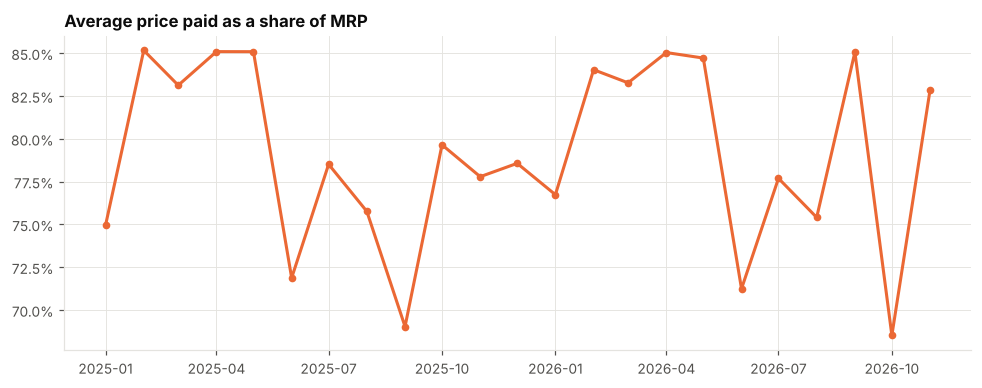

Paid 72.3% of MRP on event days vs 86.5% on normal days; 64% of order lines fall on event days


In [4]:
tx["paid_vs_mrp"] = (tx["gross_amount"] - tx["coupon_discount"]) / (tx["mrp"] * tx["quantity"])
day = tx["order_timestamp"].dt.normalize()
on_event = np.zeros(len(tx), dtype=bool)
for e in events.itertuples():
    on_event |= ((day >= e.start_date) & (day <= e.end_date)).to_numpy()
tx["on_event"] = on_event
paid = tx.set_index("order_timestamp")["paid_vs_mrp"].resample("MS").mean()
fig, ax = plt.subplots()
ax.plot(paid.index, paid.values, color=SERIES[1], marker="o", markersize=4)
ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_title("Average price paid as a share of MRP")
plt.tight_layout(); plt.show()
event_share, normal_share = tx.loc[tx.on_event, "paid_vs_mrp"].mean(), tx.loc[~tx.on_event, "paid_vs_mrp"].mean()
print(f"Paid {event_share:.1%} of MRP on event days vs {normal_share:.1%} on normal days; "
      f"{tx['on_event'].mean():.0%} of order lines fall on event days")
SUMMARY.update(paid_vs_mrp_event=float(event_share), paid_vs_mrp_normal=float(normal_share),
               event_line_share=float(tx["on_event"].mean()))

## 4. The shopping funnel

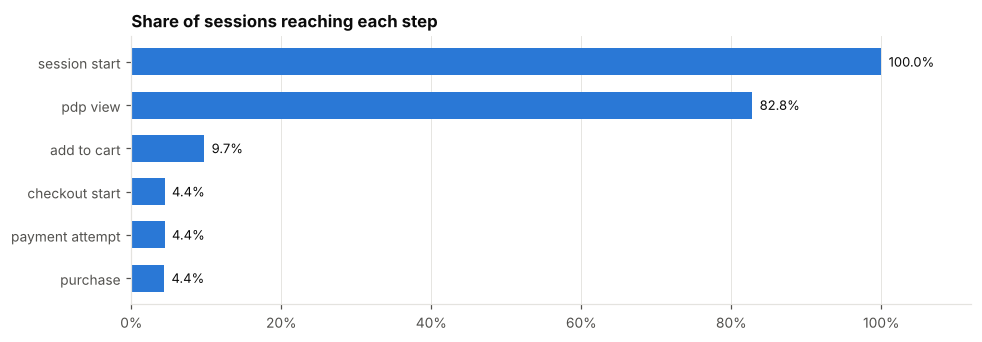

Sessions: 1,576,301; conversion to purchase: 4.38%
Cart → purchase: 45.0%


In [5]:
cs = read("clickstream", ["session_id", "event_type"])
steps = ["session_start", "pdp_view", "add_to_cart", "checkout_start", "payment_attempt", "purchase"]
reached = {s: cs.loc[cs.event_type.eq(s), "session_id"].nunique() for s in steps}
total = reached["session_start"]
funnel = pd.Series({s.replace("_", " "): reached[s] / total for s in steps})
hbar(funnel.iloc[::-1], "Share of sessions reaching each step", sort=False)
print(f"Sessions: {total:,}; conversion to purchase: {reached['purchase']/total:.2%}")
print(f"Cart → purchase: {reached['purchase']/reached['add_to_cart']:.1%}")
SUMMARY.update(sessions=int(total), session_conversion=reached["purchase"] / total,
               cart_to_purchase=reached["purchase"] / reached["add_to_cart"])

## 5. Payments and delivery problems

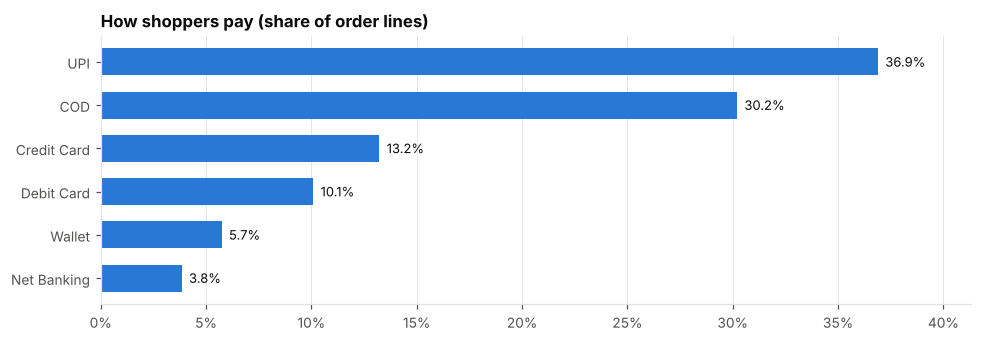

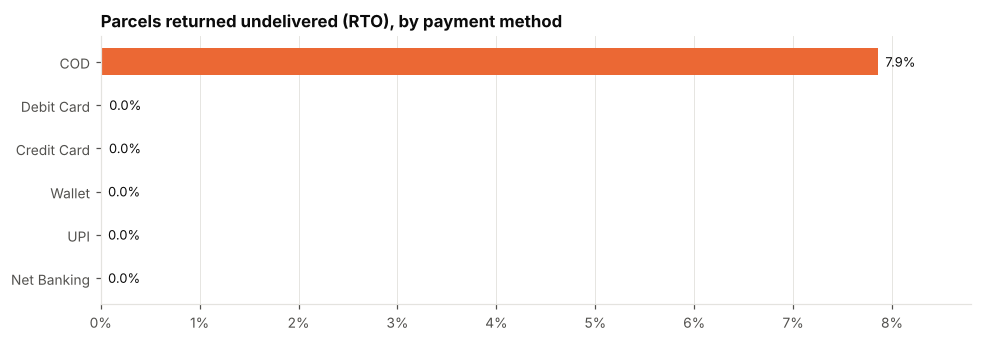

Cash on delivery RTO rate 7.9% vs 0.0% for prepaid (2349.8×)
Online payment attempts that fail: 4.0%


In [6]:
hbar(tx["payment_method"].value_counts(normalize=True), "How shoppers pay (share of order lines)", color=SERIES[0])
rto = tx.groupby("payment_method")["order_status"].apply(lambda st: st.eq("Returned to Origin").mean())
hbar(rto, "Parcels returned undelivered (RTO), by payment method", color=SERIES[1])
# RTO is a cash-on-delivery problem: the buyer refuses the parcel at the door; prepaid buyers have already paid.
cod = rto["COD"]; other = tx[tx.payment_method.ne("COD")]["order_status"].eq("Returned to Origin").mean()
print(f"Cash on delivery RTO rate {cod:.1%} vs {other:.1%} for prepaid ({cod/other:.1f}×)")
failed = cs.event_type.eq("payment_failed").sum() / max(cs.event_type.eq("payment_attempt").sum(), 1)
print(f"Online payment attempts that fail: {failed:.1%}")
SUMMARY.update(cod_rto=float(cod), prepaid_rto=float(other), payment_failure_rate=float(failed))

## 6. Returns

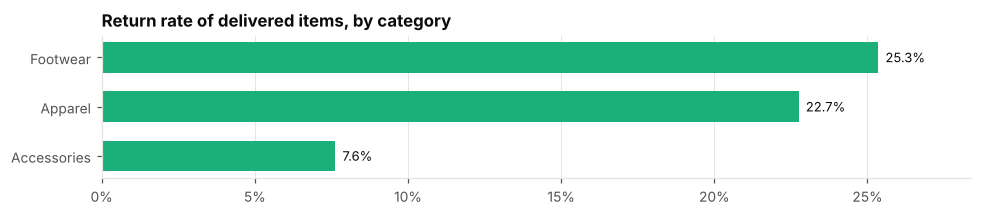

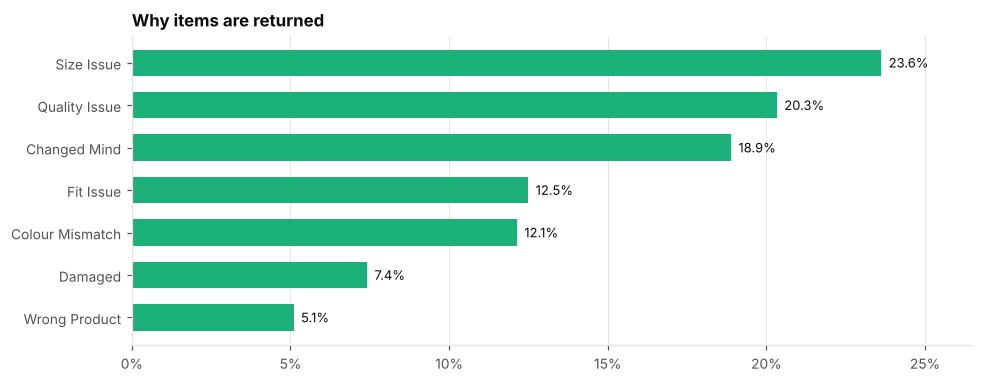

Overall return rate: 20.2%; top reason: Size Issue (24%)
Size + fit problems explain 36% of returns


In [7]:
delivered = tx[tx["delivered_at"].notna()].merge(products[["product_id", "category"]], on="product_id")
ret = delivered[delivered["return_requested_at"].notna()]
rate = ret.groupby("category").size() / delivered.groupby("category").size()
hbar(rate.dropna(), "Return rate of delivered items, by category", color=SERIES[2])
reasons = ret["return_reason"].value_counts(normalize=True)
hbar(reasons, "Why items are returned", color=SERIES[2])
print(f"Overall return rate: {len(ret)/len(delivered):.1%}; top reason: {reasons.index[0]} ({reasons.iloc[0]:.0%})")
size_fit = reasons.reindex(['Size Issue', 'Fit Issue']).sum()
print(f"Size + fit problems explain {size_fit:.0%} of returns")
SUMMARY.update(return_rate=len(ret) / len(delivered), size_fit_share=float(size_fit),
               return_rate_by_category={k: float(v) for k, v in rate.dropna().items()})

## 7. Which marketing channels bring valuable customers?

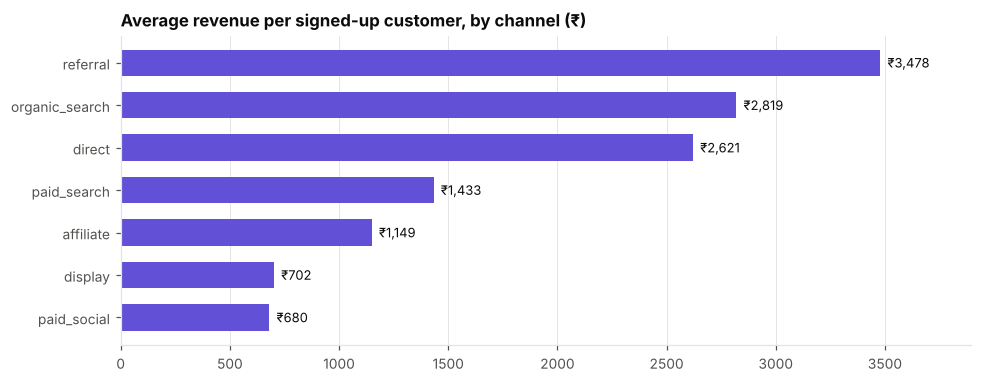

Best: referral (₹3,478); weakest: paid_social (₹680), a 5.1× gap


In [8]:
rev = realized.groupby("customer_id")["realized_revenue"].sum()
per_channel = customers.assign(revenue=customers.customer_id.map(rev).fillna(0)).groupby("signup_channel")["revenue"].mean()
hbar(per_channel, "Average revenue per signed-up customer, by channel (₹)", fmt="₹{:,.0f}", color=SERIES[6])
print(f"Best: {per_channel.idxmax()} (₹{per_channel.max():,.0f}); weakest: {per_channel.idxmin()} (₹{per_channel.min():,.0f}), "
      f"a {per_channel.max()/per_channel.min():.1f}× gap")
SUMMARY.update(best_channel=per_channel.idxmax(), best_channel_value=float(per_channel.max()),
               worst_channel=per_channel.idxmin(), worst_channel_value=float(per_channel.min()))

## 8. Repeat customers

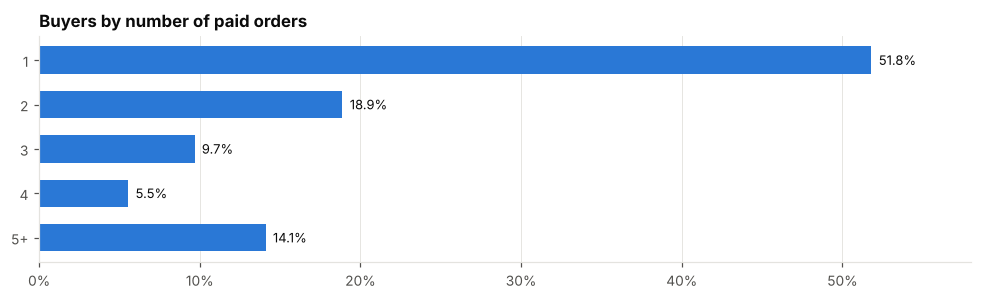

Repeat buyers: 48.2% of buyers, bringing 80.7% of revenue


In [9]:
orders_per_buyer = realized.groupby("customer_id").size()
repeat = orders_per_buyer[orders_per_buyer >= 2].index
share_repeat_rev = realized[realized.customer_id.isin(repeat)]["realized_revenue"].sum() / realized["realized_revenue"].sum()
dist = orders_per_buyer.clip(upper=5).value_counts(normalize=True).sort_index()
dist.index = [f"{i}" if i < 5 else "5+" for i in dist.index]
hbar(dist.iloc[::-1], "Buyers by number of paid orders", color=SERIES[0], sort=False)
print(f"Repeat buyers: {len(repeat)/len(orders_per_buyer):.1%} of buyers, bringing {share_repeat_rev:.1%} of revenue")
SUMMARY.update(repeat_buyer_share=len(repeat) / len(orders_per_buyer), repeat_revenue_share=float(share_repeat_rev))

## 9. Churn: who stops buying?

**Label:** `churned_90d` = no purchase in the 90 days after `snapshot_date` (monthly snapshots, from the package's
`ecommerce-sim derive`; only windows that end inside the data are kept).
**Cohort:** customers with a realized purchase in the 90 days before the snapshot.
**Business use:** each month, send a retention offer to the 10% of active customers most likely to churn.

The package also ships ready-made monthly features (`derived/customer_monthly_features`). Before using anything
like that, check it cannot see the label window: the first cell below counts feature rows that include orders
placed on or after `snapshot_date` (an earlier version of the Pantree generator had exactly this leak). Features
are then rebuilt here from the raw tables, strictly before each snapshot.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

labels = read("derived/churn_labels").rename(columns={"churned_90d": "churn_90d"})
labels["snapshot_date"] = pd.to_datetime(labels["snapshot_date"])
labels["label_window_end"] = pd.to_datetime(labels["label_window_end"])
data_end = realized["order_timestamp"].max().normalize() + pd.Timedelta(days=1)
assert (labels["label_window_end"] > labels["snapshot_date"]).all(), "label window must start after the snapshot"
assert (labels["label_window_end"] <= data_end).all(), "only fully observed label windows"

# Leakage probe on the stored feature table: orders counted vs orders strictly before snapshot_date.
stored = read("derived/customer_monthly_features")
stored["snapshot_date"] = pd.to_datetime(stored["snapshot_date"])
placed = tx.groupby("order_id").agg(customer_id=("customer_id", "first"), order_timestamp=("order_timestamp", "min"))
leaky_rows = 0
for snap, part in stored.groupby("snapshot_date"):
    strict = placed[placed["order_timestamp"] < snap].groupby("customer_id").size()
    leaky_rows += int((part.set_index("customer_id")["orders_total"] > strict.reindex(part["customer_id"]).fillna(0).to_numpy()).sum())
print(f"Stored feature rows counting orders on or after snapshot_date: {leaky_rows:,} of {len(stored):,}")
assert leaky_rows == 0, "the package's stored features leak into the label window"
SUMMARY["churn_stored_feature_leaky_rows"] = leaky_rows

Stored feature rows counting orders on or after snapshot_date: 0 of 519,256


In [11]:
returns_tbl = tx[tx["return_requested_at"].notna()][["customer_id", "return_requested_at"]].copy()
returns_tbl["return_requested_at"] = pd.to_datetime(returns_tbl["return_requested_at"])
support = read("support_contacts")
support["contact_timestamp"] = pd.to_datetime(support["contact_at"])
support["customer_sentiment"] = np.where(support["csat"] <= 2, "negative", "other")  # CSAT 1-2 = unhappy
signup = pd.to_datetime(customers.set_index("customer_id")["signup_at"])
prime = customers.set_index("customer_id")["is_prime"].astype(int)
FEATURES = ["recency_days", "tenure_days", "orders_total", "revenue_total", "avg_order_value",
            "orders_90d", "revenue_90d", "returns_90d", "support_contacts_90d", "negative_support_90d", "is_prime"]

def features_at(snapshot):
    # Point-in-time features: every source row is strictly before the snapshot date.
    hist = realized[realized["order_timestamp"] < snapshot]
    window = pd.Timedelta(days=90)
    recent = hist[hist["order_timestamp"] >= snapshot - window]
    rets = returns_tbl[(returns_tbl["return_requested_at"] < snapshot) & (returns_tbl["return_requested_at"] >= snapshot - window)]
    sup = support[(support["contact_timestamp"] < snapshot) & (support["contact_timestamp"] >= snapshot - window)]
    for source, col in ((hist, "order_timestamp"), (rets, "return_requested_at"), (sup, "contact_timestamp")):
        assert source.empty or source[col].max() < snapshot
    life = hist.groupby("customer_id").agg(orders_total=("order_id", "nunique"), revenue_total=("realized_revenue", "sum"),
                                           last_order=("order_timestamp", "max"))
    f = life.join(recent.groupby("customer_id").agg(orders_90d=("order_id", "nunique"), revenue_90d=("realized_revenue", "sum")))
    f = f.join(rets.groupby("customer_id").size().rename("returns_90d"))
    f = f.join(sup.groupby("customer_id").agg(support_contacts_90d=("contact_id", "size"),
                                              negative_support_90d=("customer_sentiment", lambda s: (s == "negative").sum())))
    f = f.fillna({c: 0 for c in ["orders_90d", "revenue_90d", "returns_90d", "support_contacts_90d", "negative_support_90d"]})
    f["recency_days"] = (snapshot - f["last_order"]).dt.days
    f["tenure_days"] = (snapshot - signup.reindex(f.index)).dt.days
    f["avg_order_value"] = f["revenue_total"] / f["orders_total"]
    f["is_prime"] = prime.reindex(f.index).fillna(0)
    return f.drop(columns=["last_order"]).assign(snapshot_date=snapshot).reset_index()

feats = pd.concat([features_at(s) for s in sorted(labels["snapshot_date"].unique())], ignore_index=True)
data = labels.merge(feats, on=["customer_id", "snapshot_date"], how="inner")
data = data[data["orders_90d"] >= 1].copy()        # cohort: bought in the 90 days before the snapshot
data["churn"] = data["churn_90d"].astype(int)
print(f"{len(data):,} customer-snapshots, {data['customer_id'].nunique():,} customers, churn rate {data['churn'].mean():.1%}")

71,538 customer-snapshots, 16,327 customers, churn rate 59.0%


In [12]:
# Temporal split with an embargo: a split's labels (snapshot + 90 days) must end before the next split starts.
snaps = sorted(data["snapshot_date"].unique())
test_snaps = snaps[-2:]
val_snaps = [s for s in snaps if s + pd.Timedelta(days=90) < test_snaps[0]][-2:]
train_snaps = [s for s in snaps if s + pd.Timedelta(days=90) < val_snaps[0]]
split = {"train": data[data["snapshot_date"].isin(train_snaps)], "validation": data[data["snapshot_date"].isin(val_snaps)],
         "test": data[data["snapshot_date"].isin(test_snaps)]}
assert split["train"]["label_window_end"].max() < split["validation"]["snapshot_date"].min()
assert split["validation"]["label_window_end"].max() < split["test"]["snapshot_date"].min()
for name, part in split.items():
    print(f"{name:10s} snapshots {part['snapshot_date'].min():%Y-%m}..{part['snapshot_date'].max():%Y-%m}  "
          f"rows {len(part):6,}  churn rate {part['churn'].mean():.1%}")
X = {k: v[FEATURES] for k, v in split.items()}
y = {k: v["churn"].to_numpy() for k, v in split.items()}

train      snapshots 2025-02..2025-11  rows 27,203  churn rate 58.3%
validation snapshots 2026-03..2026-04  rows 10,787  churn rate 65.2%
test       snapshots 2026-07..2026-08  rows  9,638  churn rate 55.0%


In [13]:
# (a) rule: churn risk = days since last order; threshold chosen on validation (best F1)
thresholds = np.arange(15, 91, 5)
best_t = max(thresholds, key=lambda t: f1_score(y["validation"], (X["validation"]["recency_days"] > t).astype(int)))
models = {
    "Recency rule": None,
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=0)),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=0),
}
scores_test = {"Recency rule": X["test"]["recency_days"].to_numpy(dtype=float)}
val_auc = {}
for name, model in models.items():
    if model is None:
        continue
    model.fit(X["train"], y["train"])
    val_auc[name] = roc_auc_score(y["validation"], model.predict_proba(X["validation"])[:, 1])
    print(f"{name}: validation AUC {val_auc[name]:.3f}")
    scores_test[name] = model.predict_proba(X["test"])[:, 1]
best_name = max(val_auc, key=val_auc.get)  # chosen on validation, never on test
print(f"Chosen on validation: {best_name}")
print(f"Recency rule: flag customers with no order for more than {best_t} days "
      f"(validation AUC {roc_auc_score(y['validation'], X['validation']['recency_days']):.3f})")

# Cross-check: the same model on the package's stored (point-in-time) feature table.
leaky_cols = ["tenure_days", "orders_total", "revenue_total", "days_since_last_order", "orders_90d", "revenue_90d",
              "returns_90d", "sessions_30d", "support_contacts_90d", "is_prime"]
lk = {k: v[["customer_id", "snapshot_date", "churn"]].merge(stored, on=["customer_id", "snapshot_date"]) for k, v in split.items()}
leaky_model = HistGradientBoostingClassifier(random_state=0).fit(lk["train"][leaky_cols], lk["train"]["churn"])
leaky_auc = roc_auc_score(lk["test"]["churn"], leaky_model.predict_proba(lk["test"][leaky_cols])[:, 1])

Logistic regression: validation AUC 0.712


Gradient boosting: validation AUC 0.695
Chosen on validation: Logistic regression
Recency rule: flag customers with no order for more than 15 days (validation AUC 0.621)


In [14]:
rng = np.random.default_rng(0)
test_customers = split["test"]["customer_id"].to_numpy()
unique_customers = np.unique(test_customers)
rows_by_customer = pd.Series(np.arange(len(test_customers))).groupby(test_customers).apply(np.array)
boot_rows = [np.concatenate(rows_by_customer.loc[rng.choice(unique_customers, len(unique_customers))].to_list()) for _ in range(500)]
base = y["test"].mean()

def top_decile(score):
    cut = np.quantile(score, 0.9)
    precision = y["test"][score >= cut].mean()
    return precision, precision / base

rows = []
for name, score in scores_test.items():
    aucs = [roc_auc_score(y["test"][r], score[r]) for r in boot_rows]
    precision, lift = top_decile(score)
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y["test"], score),
                 "AUC 95% CI": f"{np.quantile(aucs, .025):.3f}–{np.quantile(aucs, .975):.3f}",
                 "PR-AUC": average_precision_score(y["test"], score), "base rate": base,
                 "top-10% precision": precision, "top-10% lift": lift,
                 "Brier": brier_score_loss(y["test"], score) if name != "Recency rule" else np.nan})
table = pd.DataFrame(rows).set_index("model")
print(table.round(3).to_string())
print(f"\nCross-check: gradient boosting on the package's stored features reaches test AUC {leaky_auc:.3f} "
      f"vs {table.loc['Gradient boosting', 'ROC-AUC']:.3f} on the notebook's rebuilt features (both leakage-free).")
best = table.loc[best_name]
SUMMARY["churn"] = {"model": best_name, "test_auc": float(best["ROC-AUC"]), "test_auc_ci": best["AUC 95% CI"],
                    "pr_auc": float(best["PR-AUC"]), "base_rate": float(base),
                    "top_decile_precision": float(best["top-10% precision"]),
                    "top_decile_lift": float(best["top-10% lift"]), "brier": float(best["Brier"]),
                    "logreg_auc": float(table.loc["Logistic regression", "ROC-AUC"]),
                    "hgb_auc": float(table.loc["Gradient boosting", "ROC-AUC"]),
                    "rule_auc": float(table.loc["Recency rule", "ROC-AUC"]), "stored_features_auc": float(leaky_auc),
                    "test_rows": int(len(y["test"]))}

                     ROC-AUC   AUC 95% CI  PR-AUC  base rate  top-10% precision  top-10% lift  Brier
model                                                                                               
Recency rule           0.609  0.599–0.620   0.638       0.55              0.709         1.289    NaN
Logistic regression    0.723  0.711–0.734   0.730       0.55              0.794         1.442  0.210
Gradient boosting      0.708  0.697–0.722   0.713       0.55              0.769         1.397  0.214

Cross-check: gradient boosting on the package's stored features reaches test AUC 0.734 vs 0.708 on the notebook's rebuilt features (both leakage-free).


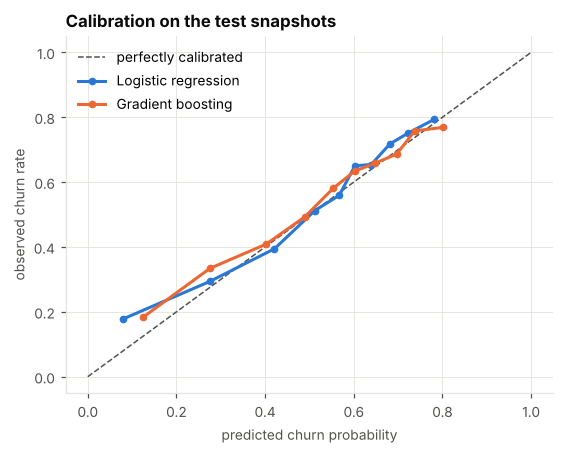

In [15]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="perfectly calibrated")
for color, name in zip(SERIES, ["Logistic regression", "Gradient boosting"]):
    frac, mean_pred = calibration_curve(y["test"], scores_test[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, color=color, marker="o", markersize=4, label=name)
ax.set_title("Calibration on the test snapshots"); ax.set_xlabel("predicted churn probability"); ax.set_ylabel("observed churn rate")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

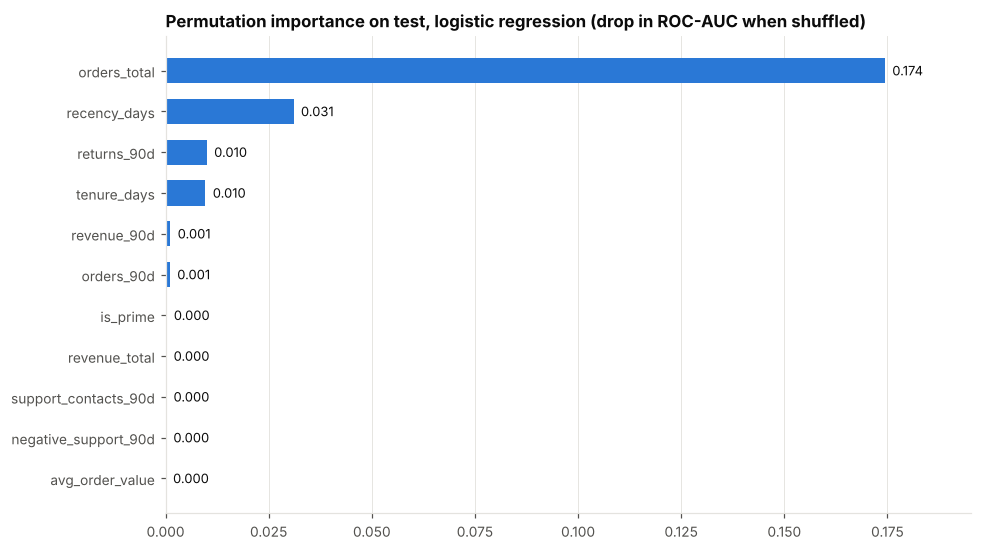

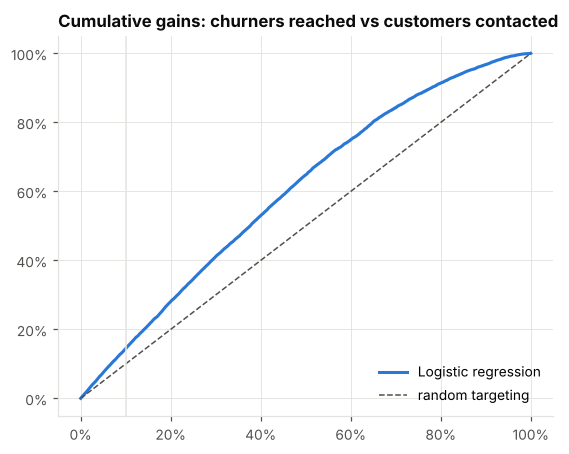

In [16]:
model = models[best_name]
imp = permutation_importance(model, X["test"], y["test"], scoring="roc_auc", n_repeats=10, random_state=0)
importance = pd.Series(imp.importances_mean, index=FEATURES)
hbar(importance, f"Permutation importance on test, {best_name.lower()} (drop in ROC-AUC when shuffled)", fmt="{:.3f}", color=SERIES[0])

order = np.argsort(-scores_test[best_name])
captured = np.cumsum(y["test"][order]) / y["test"].sum()
share = np.arange(1, len(order) + 1) / len(order)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot(share, captured, color=SERIES[0], label=best_name)
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="random targeting")
ax.axvline(0.1, color=GRID, lw=1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Cumulative gains: churners reached vs customers contacted"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
top10_capture = float(captured[int(0.1 * len(order)) - 1])
SUMMARY["churn"]["top_decile_capture"] = top10_capture
SUMMARY["churn"]["top_features"] = importance.sort_values(ascending=False).head(3).index.tolist()

In [17]:
c = SUMMARY["churn"]
print(f"{c['model']}: targeting the top 10% of customers by predicted risk catches {c['top_decile_capture']:.0%} of churners "
      f"at {c['top_decile_lift']:.1f}× the base rate ({c['top_decile_precision']:.0%} of those contacted churn vs {c['base_rate']:.0%} overall).")

Logistic regression: targeting the top 10% of customers by predicted risk catches 14% of churners at 1.4× the base rate (79% of those contacted churn vs 55% overall).


**Limitations.** The data is synthetic: a customer's visits fade after a personal "lapse" time, and the strongest
driver of churn (that hidden lapse time) is only partly visible through recency and frequency, so the leakage-free
model is modest; that is the honest result. Real data would differ.

## 10. Recommendation evaluation
Results from `python -m recommendations.evaluate`. For every order in the held-out final period, each method ranks
the same candidate list using only what was known an hour before the order. NDCG@10 rewards putting the products
the shopper actually bought near the top (1.0 = perfect, 0 = none in the top 10).

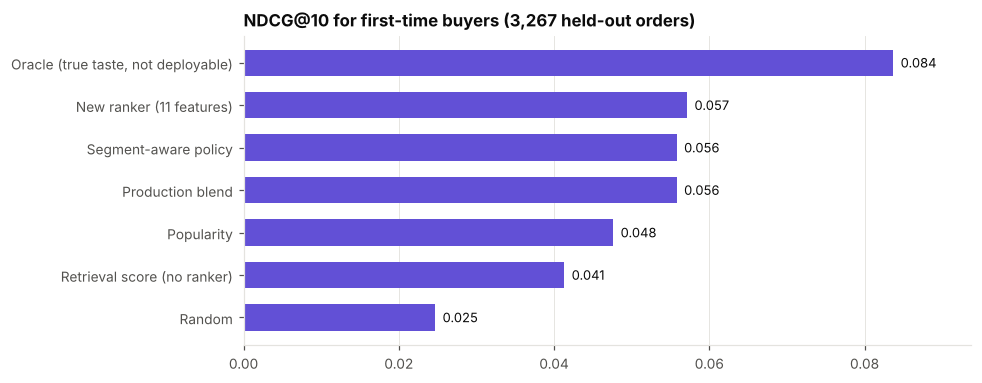

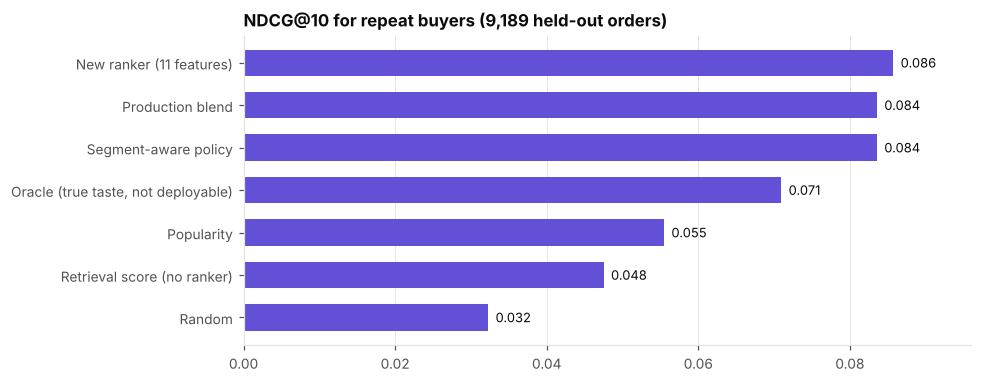

Candidate lists contained a bought product for 34.2% of test orders
new_ranker_vs_retrieval: +0.0323 (95% CI +0.0292 to +0.0353)
new_ranker_vs_popularity: +0.0248 (95% CI +0.0219 to +0.0278)
new_ranker_vs_random: +0.0479 (95% CI +0.0440 to +0.0516)
segment_aware_vs_retrieval: +0.0304 (95% CI +0.0280 to +0.0328)
segment_aware_vs_popularity: +0.0229 (95% CI +0.0202 to +0.0254)
segment_aware_vs_production_blend: +0.0000 (95% CI +0.0000 to +0.0000)


In [18]:
report_path = ROOT / "recommendations" / "reports" / "evaluation_report.json"
if report_path.exists():
    report = json.loads(report_path.read_text())
    names = {"random": "Random", "popularity": "Popularity", "retrieval": "Retrieval score (no ranker)",
             "new_ranker": "New ranker (11 features)",
             "production_blend": "Production blend", "segment_aware": "Segment-aware policy",
             "oracle": "Oracle (true taste, not deployable)"}
    for group, label in [("first_order", "first-time buyers"), ("repeat_order", "repeat buyers")]:
        res = report["results"]["end_to_end"][group]
        ndcg = pd.Series({names[o]: m["@10"]["ndcg"] for o, m in res["orderings"].items() if m["@10"]})
        hbar(ndcg, f"NDCG@10 for {label} ({res['orders']:,} held-out orders)", fmt="{:.3f}", color=SERIES[6])
    r = report["retrieval"]
    print(f"Candidate lists contained a bought product for {r['pool_coverage']:.1%} of test orders")
    for name, c in report["comparisons_ndcg10"].items():
        print(f"{name}: {c['mean_diff']:+.4f} (95% CI {c['ci_low']:+.4f} to {c['ci_high']:+.4f})")
else:
    print("Run `python -m recommendations.evaluate` first.")

In [19]:
summary_path = ROOT / "recommendations" / "reports" / "insights_summary.json"
summary_path.write_text(json.dumps(SUMMARY, indent=2, default=float))
print(f"Wrote {summary_path.relative_to(ROOT)}")

Wrote recommendations/reports/insights_summary.json
